# What a satellite measures

A satellite image is a grid of measurements of **light**: how much electromagnetic energy reached the sensor from
each patch of ground, in a few narrow ranges of wavelength called **bands**. To read an image well you need a little
physics (what light is and where it comes from), a little chemistry and biology (why snow, leaves, water and rock
reflect differently) and a little arithmetic (how the numbers in the file become physical quantities).

This notebook builds that up from first principles and checks each idea on a real image: Sentinel-2 over the Hunza
valley in the Karakoram in spring, with snow, glaciers, bare rock, villages, orchards and a river in one scene.

What you will learn: waves and photons; Planck's law and why the Sun and the Earth are seen in different bands;
the atmosphere's windows; bands and the four kinds of resolution; digital numbers, scale factors and reflectance;
histograms and contrast stretches; true- and false-colour composites; spectral signatures; and what atmospheric
correction changes.

In [1]:
import importlib.util, subprocess, sys
need = {"pystac_client": "pystac-client", "planetary_computer": "planetary-computer", "rasterio": "rasterio"}
missing = [p for m, p in need.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pystac_client, planetary_computer, rasterio
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds
from rasterio.enums import Resampling
plt.rcParams.update({"figure.dpi": 110})

# Light as a wave and as a particle

Light is an **electromagnetic wave**: electric and magnetic fields oscillating together, travelling at the speed of
light $c \approx 3.00 \times 10^8$ m/s in a vacuum. Its **wavelength** $\lambda$ (distance between crests) and
**frequency** $\nu$ (crests per second) are tied by

$$c = \lambda \nu .$$

Light also arrives in packets, **photons**, each carrying energy

$$E = h\nu = \frac{hc}{\lambda},$$

where $h = 6.626 \times 10^{-34}$ J s is Planck's constant. Shorter wavelength means more energy per photon: an
ultraviolet photon can break chemical bonds (sunburn), an infrared one only warms. Remote sensing uses wavelengths from
about 0.4 micrometres ($\mu$m, millionths of a metre; visible light) to about 1 metre (radar).

| Region | Wavelength | Used for |
|---|---|---|
| visible (blue, green, red) | 0.4 to 0.7 $\mu$m | colour images, water, sediment |
| near infrared (NIR) | 0.7 to 1.3 $\mu$m | vegetation |
| shortwave infrared (SWIR) | 1.3 to 3 $\mu$m | snow versus cloud, moisture, minerals |
| thermal infrared (TIR) | 8 to 14 $\mu$m | surface temperature |
| microwave (radar) | 1 mm to 1 m | through cloud, day and night; roughness and moisture |

In [2]:
h, c, k = 6.62607015e-34, 2.99792458e8, 1.380649e-23        # Planck, speed of light, Boltzmann (exact SI values)
for name, lam in [("blue", 0.49e-6), ("near infrared", 0.84e-6), ("shortwave infrared", 1.61e-6), ("thermal", 10.9e-6), ("radar C-band", 0.055)]:
    print(f"{name:20s} wavelength {lam:9.2e} m   frequency {c / lam:9.2e} Hz   photon energy {h * c / lam:9.2e} J")

blue                 wavelength  4.90e-07 m   frequency  6.12e+14 Hz   photon energy  4.05e-19 J
near infrared        wavelength  8.40e-07 m   frequency  3.57e+14 Hz   photon energy  2.36e-19 J
shortwave infrared   wavelength  1.61e-06 m   frequency  1.86e+14 Hz   photon energy  1.23e-19 J
thermal              wavelength  1.09e-05 m   frequency  2.75e+13 Hz   photon energy  1.82e-20 J
radar C-band         wavelength  5.50e-02 m   frequency  5.45e+09 Hz   photon energy  3.61e-24 J


# Why the Sun and the Earth are seen in different bands

Every object warmer than absolute zero gives off radiation. An ideal emitter, a **black body**, at temperature $T$
(kelvin) emits at each wavelength the amount given by **Planck's law**:

$$B_\lambda(T) = \frac{2hc^2}{\lambda^5}\,\frac{1}{e^{hc/(\lambda k T)} - 1},$$

with $k = 1.381 \times 10^{-23}$ J/K, Boltzmann's constant. Two consequences follow, both checked numerically below.

* **Wien's law**: the peak lies at $\lambda_{max} = b / T$ with $b = 2898\ \mu$m K. The Sun's surface, near 5,772 K,
  peaks at about 0.5 $\mu$m, in green light, which is why our eyes evolved for that range. The Earth's surface, near
  288 K, peaks near 10 $\mu$m, in the thermal infrared.
* **Stefan-Boltzmann law**: the total emitted per square metre is $\sigma T^4$, with
  $\sigma = 5.67 \times 10^{-8}$ W m$^{-2}$ K$^{-4}$. Doubling the temperature multiplies the output sixteen times.

So in daylight, visible and shortwave sensors see **reflected sunlight**, and thermal sensors see the Earth's own
**emitted heat**, by day and night. The curves cross around 4 $\mu$m, the boundary between the two.

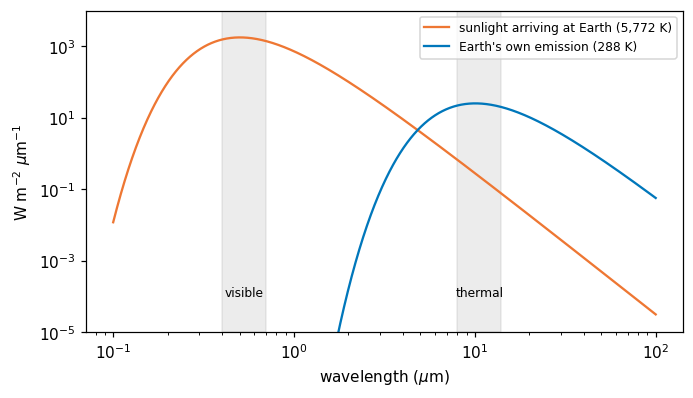

Sun: peak from the curve 0.50 um, Wien's law 0.50 um, total sigma*T^4 = 62,938,588 W/m2
Earth: peak from the curve 10.05 um, Wien's law 10.06 um, total sigma*T^4 = 390 W/m2


In [3]:
def planck(lam, T):
    return 2 * h * c**2 / lam**5 / np.expm1(h * c / (lam * k * T))

lam = np.logspace(-7, -4, 2000)                         # 0.1 to 100 micrometres
sun, earth = planck(lam, 5772), planck(lam, 288)
sun_at_earth = sun * (6.957e8 / 1.496e11) ** 2          # sunlight dilutes with the square of distance (solar radius / Earth-Sun distance)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.loglog(lam * 1e6, sun_at_earth * np.pi * 1e-6, color="#ee7733", label="sunlight arriving at Earth (5,772 K)")
ax.loglog(lam * 1e6, earth * np.pi * 1e-6, color="#0077bb", label="Earth's own emission (288 K)")
for lo, hi, lab in [(0.4, 0.7, "visible"), (8, 14, "thermal")]:
    ax.axvspan(lo, hi, color="grey", alpha=0.15)
    ax.text(np.sqrt(lo * hi), 1e-4, lab, ha="center", fontsize=8)
ax.set_ylim(1e-5, 1e4)
ax.set_xlabel("wavelength ($\\mu$m)")
ax.set_ylabel("W m$^{-2}$ $\\mu$m$^{-1}$")
ax.legend(fontsize=8)
plt.show()
for T, who in [(5772, "Sun"), (288, "Earth")]:
    peak = lam[np.argmax(planck(lam, T))] * 1e6
    print(f"{who}: peak from the curve {peak:.2f} um, Wien's law {2898 / T:.2f} um, total sigma*T^4 = {5.670374e-8 * T**4:,.0f} W/m2")

# The atmosphere's windows

Between the Sun, the ground and the satellite, light crosses the atmosphere twice. Gases absorb at particular
wavelengths, because each molecule can only take up energy in steps that match its vibrations and rotations: **water
vapour** absorbs strongly near 1.4, 1.9 and 2.7 $\mu$m and across much of the thermal infrared; **carbon dioxide** near
2.7, 4.3 and 15 $\mu$m; **ozone** absorbs ultraviolet. The ranges that pass are **atmospheric windows**, and satellite
bands are placed inside them. Even inside windows, small particles and molecules **scatter** light, most strongly at
short wavelengths (Rayleigh scattering goes as $1/\lambda^4$): the reason the sky is blue and why the blue band of any
image looks hazy. Correcting for this is **atmospheric correction**, compared later in this notebook.

# Bands and the four resolutions

A sensor records each band separately. Its design is a set of trade-offs, usually described as four resolutions:

* **spatial**: the ground size of a pixel (Sentinel-2: 10, 20 or 60 m; Landsat: 30 m; MODIS: 250 to 1,000 m);
* **spectral**: how many bands, and how narrow (Sentinel-2 has 13);
* **temporal**: how often the same place is seen (Sentinel-2: every 5 days with two satellites; MODIS: daily);
* **radiometric**: how finely brightness is divided (12 bits = 4,096 levels for Sentinel-2).

Finer pixels mean narrower swaths and fewer visits, so no sensor is best at all four. The catalogue describes each
band; we read those descriptions directly.

In [4]:
catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=planetary_computer.sign_inplace)
BBOX = [74.55, 36.25, 74.75, 36.40]                        # Hunza valley around Karimabad and Aliabad
items = sorted(catalog.search(collections=["sentinel-2-l2a"], bbox=BBOX, datetime="2025-03-01/2025-04-30",
                              query={"eo:cloud_cover": {"lt": 15}}).items(), key=lambda i: i.properties["eo:cloud_cover"])
item = items[0]
print("image:", item.id, "| date", item.properties["datetime"][:10], "| sun elevation",
      round(90 - item.properties["s2:mean_solar_zenith"], 1), "degrees")
rows = []
for key, a in item.assets.items():
    for b in a.extra_fields.get("eo:bands", []):
        rows.append(dict(asset=key, band=b.get("description", b["name"]), centre_um=b.get("center_wavelength"),
                         width_um=b.get("full_width_half_max"), pixel_m=a.extra_fields.get("gsd")))
bands = pd.DataFrame(rows).dropna(subset=["centre_um"]).sort_values("centre_um").reset_index(drop=True)
bands

image: S2B_MSIL2A_20250429T054639_R048_T43SDA_20250429T075112 | date 2025-04-29 | sun elevation 64.2 degrees


,asset,band,centre_um,width_um,pixel_m
0,B01,Band 1 - Coastal aerosol,0.443,0.027,60
1,B02,Band 2 - Blue,0.490,0.098,10
2,visual,Band 2 - Blue,0.490,0.098,10
3,B03,Band 3 - Green,0.560,0.045,10
4,visual,Band 3 - Green,0.560,0.045,10
5,visual,Band 4 - Red,0.665,0.038,10
6,B04,Band 4 - Red,0.665,0.038,10
7,B05,Band 5 - Vegetation red edge 1,0.704,0.019,20
8,B06,Band 6 - Vegetation red edge 2,0.740,0.018,20
9,B07,Band 7 - Vegetation red edge 3,0.783,0.028,20


# From digital numbers to reflectance

A file does not store "brightness" directly. It stores **digital numbers** (DNs): whole numbers, chosen so that the
data fit in 16-bit integers and compress well. To get a physical quantity you apply the product's **scale** and
**offset**:

$$\text{reflectance} = \frac{\text{DN} + \text{offset}}{\text{quantification value}}.$$

For Sentinel-2 the quantification value is 10,000, and since processing baseline 04.00 (January 2022) the offset is
-1,000, so that small negative values from the correction need not be cut off. Forgetting the offset makes every
reflectance 0.1 too high: a classic, silent error. **Reflectance** is the fraction of incoming sunlight reflected,
from 0 (absorbs everything) to 1 (reflects everything); fresh snow reaches about 0.9 in visible light.

DN 0 here means *no data* (outside the image), and must be masked before any statistics.

**Reflectance above 1?** The output below shows a few values above 1, which no real surface reflects. Level-2A
images are corrected for terrain as well as for the atmosphere: the processor divides out how much sunlight each slope
received, using a DEM. On steep slopes that received little sun, that division magnifies small errors and can
overshoot. The terrain notebook checks this on the same image. Treat such values as artefacts of the correction and
leave them out of statistics, or cap them, saying which you did.

In [5]:
def read(item, key, bbox, shape=None):
    with rasterio.open(item.assets[key].href) as src:
        win = from_bounds(*transform_bounds("EPSG:4326", src.crs, *bbox), src.transform)
        kw = dict(out_shape=shape, resampling=Resampling.bilinear) if shape else {}
        return src.read(1, window=win, **kw), src.profile

b04, prof = read(item, "B04", BBOX)
shape = b04.shape
dn = {b: read(item, b, BBOX, shape)[0] for b in ["B02", "B03", "B04", "B08", "B11", "B12"]}
baseline = float(item.properties["s2:processing_baseline"])
offset = -1000 if baseline >= 4.0 else 0
refl = {b: np.where(v == 0, np.nan, (v.astype("float32") + offset) / 10000) for b, v in dn.items()}
print("processing baseline", baseline, "-> offset", offset, "| data type in the file:", dn["B04"].dtype,
      "| grid:", shape, "pixels of", round(prof["transform"].a), "m")
print("red band, raw DN: min", int(dn["B04"][dn["B04"] > 0].min()), "max", int(dn["B04"].max()),
      "| reflectance: min", round(float(np.nanmin(refl["B04"])), 3), "max", round(float(np.nanmax(refl["B04"])), 3))

processing baseline 5.11 -> offset -1000 | data type in the file: uint16 | grid: (1670, 1801) pixels of 10 m
red band, raw DN: min 999 max 17148 | reflectance: min -0.0 max 1.615


# Histograms and contrast

A **histogram** counts how many pixels have each value. It is the first thing to look at in any band: it shows the
range, whether there are several kinds of surface (several peaks), and whether values pile up at the top
(**saturation**, common over bright snow) or bottom.

Screens show 256 levels per colour, so to display a band you choose which values map to black and white. Using the
minimum and maximum wastes the range on a few extreme pixels; a **percentile stretch** (here the 2nd to 98th
percentile) maps most pixels across the full range. Stretching changes only the picture, never the data you analyse.

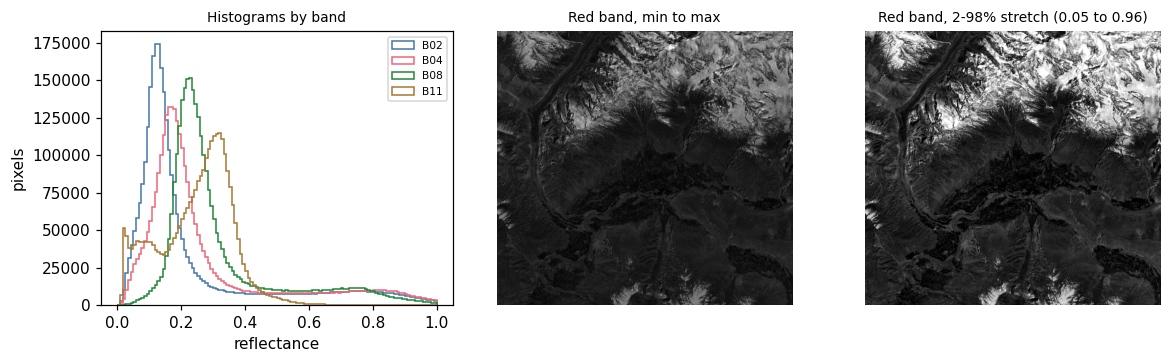

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.4))
for b, col in [("B02", "#4477aa"), ("B04", "#ee6677"), ("B08", "#228833"), ("B11", "#aa7733")]:
    ax[0].hist(refl[b][np.isfinite(refl[b])], bins=120, range=(0, 1.0), histtype="step", color=col, label=b)
ax[0].set_xlabel("reflectance")
ax[0].set_ylabel("pixels")
ax[0].legend(fontsize=7)
ax[0].set_title("Histograms by band", fontsize=9)
red = refl["B04"]
ax[1].imshow(red, cmap="gray", vmin=np.nanmin(red), vmax=np.nanmax(red))
ax[1].set_title("Red band, min to max", fontsize=9)
lo, hi = np.nanpercentile(red, [2, 98])
ax[2].imshow(red, cmap="gray", vmin=lo, vmax=hi)
ax[2].set_title(f"Red band, 2-98% stretch ({lo:.2f} to {hi:.2f})", fontsize=9)
for a in ax[1:]:
    a.set_axis_off()
plt.tight_layout()
plt.show()

# Colour composites

A colour picture is three bands shown as red, green and blue. **True colour** puts the red, green and blue bands in
those places, as our eyes would see. **False colour** uses bands we cannot see. Two standard ones:

* **NIR, red, green** (the "colour infrared" composite): healthy vegetation is bright red, because leaves reflect
  near infrared strongly. The reason is biological: inside a leaf, light scatters many times at the boundaries between
  water-filled cells and air spaces in the spongy mesophyll, and with no pigment absorbing in the near infrared, much
  of it comes back out. Chlorophyll, meanwhile, absorbs red and blue light for photosynthesis, so leaves are dark there.
* **SWIR, NIR, red**: snow and ice turn cyan-blue and clouds stay white, because ice absorbs strongly in the shortwave
  infrared while cloud droplets, being small, still scatter it. This is how snow is told from cloud.

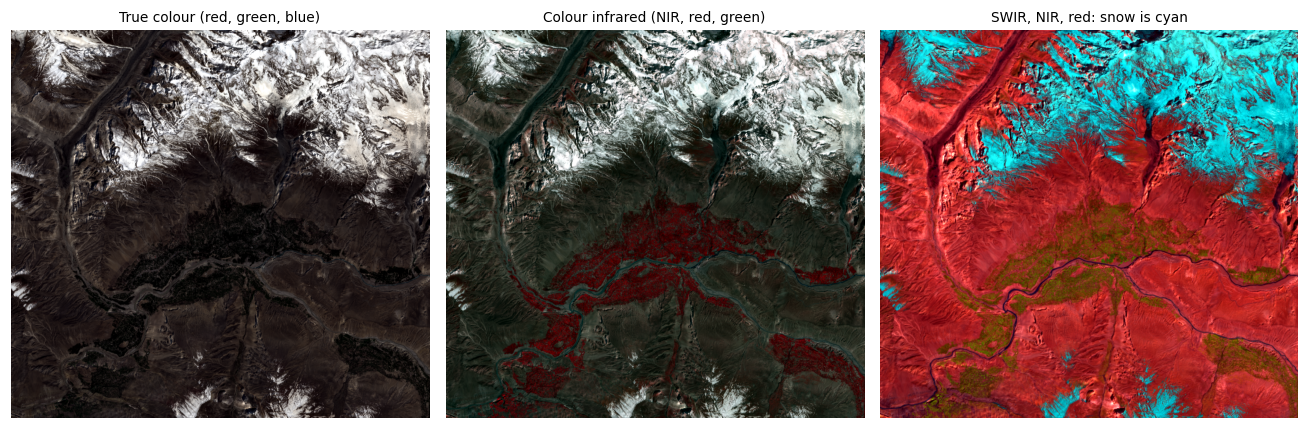

In [7]:
def stretch(a, p=(2, 98)):
    lo, hi = np.nanpercentile(a, p)
    return np.clip((a - lo) / (hi - lo), 0, 1)

def rgb(r, g, b):
    return np.dstack([stretch(refl[r]), stretch(refl[g]), stretch(refl[b])])

fig, ax = plt.subplots(1, 3, figsize=(12, 4.2))
for a, (r, g, b), title in zip(ax, [("B04", "B03", "B02"), ("B08", "B04", "B03"), ("B11", "B08", "B04")],
                               ["True colour (red, green, blue)", "Colour infrared (NIR, red, green)", "SWIR, NIR, red: snow is cyan"]):
    a.imshow(rgb(r, g, b))
    a.set_title(title, fontsize=9)
    a.set_axis_off()
plt.tight_layout()
plt.show()

# Spectral signatures

Plotting reflectance against wavelength for one kind of surface gives its **spectral signature**, the basis of every
classification. Below we pick pixels by simple, stated rules and plot their median signatures. Each shape has a
physical cause:

* **snow**: very bright in visible and near infrared (ice crystals scatter), dark in SWIR (ice absorbs; the absorption
  grows with grain size, so old snow is darker in SWIR than fresh);
* **vegetation**: low in blue and red (chlorophyll absorbs), a small green peak, a steep rise at about 0.7 $\mu$m (the
  **red edge**) to a high NIR plateau, then lower in SWIR where leaf water absorbs;
* **water**: dark everywhere beyond green, because water absorbs near and shortwave infrared almost completely; a silty
  river is brighter in visible light from the suspended sediment;
* **bare rock and soil**: rising gently with wavelength, with the details set by minerals (iron oxides absorb blue,
  clays and carbonates have SWIR absorption features).

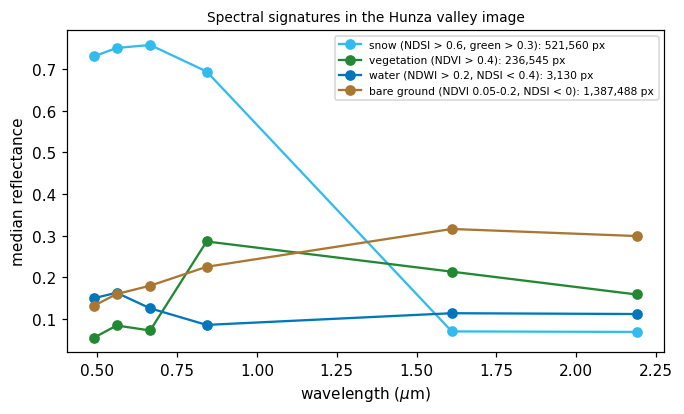

In [8]:
ndsi = (refl["B03"] - refl["B11"]) / (refl["B03"] + refl["B11"])
ndvi = (refl["B08"] - refl["B04"]) / (refl["B08"] + refl["B04"])
ndwi = (refl["B03"] - refl["B08"]) / (refl["B03"] + refl["B08"])
rules = {"snow (NDSI > 0.6, green > 0.3)": (ndsi > 0.6) & (refl["B03"] > 0.3),
         "vegetation (NDVI > 0.4)": ndvi > 0.4,
         "water (NDWI > 0.2, NDSI < 0.4)": (ndwi > 0.2) & (ndsi < 0.4),
         "bare ground (NDVI 0.05-0.2, NDSI < 0)": (ndvi > 0.05) & (ndvi < 0.2) & (ndsi < 0)}
centre = dict(zip(bands.asset, bands.centre_um))
order = ["B02", "B03", "B04", "B08", "B11", "B12"]
fig, ax = plt.subplots(figsize=(7, 3.8))
for (name, m), col in zip(rules.items(), ["#33bbee", "#228833", "#0077bb", "#aa7733"]):
    med = [np.nanmedian(refl[b][m]) for b in order]
    ax.plot([centre[b] for b in order], med, "-o", color=col, label=f"{name}: {int(m.sum()):,} px")
ax.set_xlabel("wavelength ($\\mu$m)")
ax.set_ylabel("median reflectance")
ax.legend(fontsize=7)
ax.set_title("Spectral signatures in the Hunza valley image", fontsize=9)
plt.show()

# What atmospheric correction changes

The image above is **Level-2A**: surface reflectance, after the Sen2Cor processor removed the effects of the
atmosphere (scattering by air and aerosol, absorption by water vapour). The same scene also exists as **Level-1C**:
**top-of-atmosphere** reflectance, what the satellite actually sees. Comparing the two shows what the atmosphere adds:
a haze that lifts dark surfaces most in the blue band (Rayleigh scattering), and much less in the infrared.

Level-1C files on Amazon are in a "requester pays" bucket (reading them needs a paid AWS account), so this comparison
uses Google Earth Engine, which holds both levels of the same image (see the data access notebook for setting it up).
The pixels are chosen by the same water and vegetation rules, applied to the surface image.

In [9]:
import os
from pathlib import Path
EE_PROJECT = os.environ.get("EE_PROJECT")
if EE_PROJECT and (Path.home() / ".config" / "earthengine" / "credentials").exists():
    import ee
    ee.Initialize(project=EE_PROJECT)
    region = ee.Geometry.Rectangle(BBOX)
    pid = item.properties["s2:product_uri"].replace(".SAFE", "") if "s2:product_uri" in item.properties else None
    day = ee.Date(item.properties["datetime"][:10])
    pick = lambda c: ee.Image(ee.ImageCollection(c).filterBounds(region).filterDate(day, day.advance(1, "day")).first())
    sr, toa_img = pick("COPERNICUS/S2_SR_HARMONIZED"), pick("COPERNICUS/S2_HARMONIZED")
    s = sr.divide(10000)       # Earth Engine's harmonized collections have the -1000 offset already removed
    water_m = s.normalizedDifference(["B3", "B8"]).gt(0.2).And(s.normalizedDifference(["B3", "B11"]).lt(0.4))
    veg_m = s.normalizedDifference(["B8", "B4"]).gt(0.4)
    out = {}
    for label, m in [("water", water_m), ("vegetation", veg_m)]:
        for level, img in [("top of atmosphere", toa_img), ("surface", sr)]:
            v = img.select(["B2", "B4", "B8", "B11"]).divide(10000).updateMask(m).reduceRegion(ee.Reducer.median(), region, 20, maxPixels=1e9).getInfo()
            out[f"{label}, {level}"] = v
    tab = pd.DataFrame(out).T.rename(columns={"B2": "blue", "B4": "red", "B8": "NIR", "B11": "SWIR"})[["blue", "red", "NIR", "SWIR"]].round(3)
    print(tab.to_string())
else:
    print("Earth Engine not set up here: see the data access notebook. The comparison is skipped.")

                                blue    red    NIR   SWIR
water, top of atmosphere       0.161  0.126  0.095  0.099
water, surface                 0.143  0.116  0.080  0.101
vegetation, top of atmosphere  0.104  0.087  0.253  0.188
vegetation, surface            0.057  0.074  0.287  0.212


Reading the table: over vegetation, which is dark in blue, the top-of-atmosphere blue value is almost twice the
surface value: about half of what the satellite records there is light scattered by the air itself (Rayleigh
scattering, strongest at short wavelengths), which the correction removes. In the near infrared the correction works
the other way, raising the value, because it restores light that aerosol and water vapour absorbed on the way. The
river here is silty and bright, so the haze makes up a smaller share of its signal and its values change less.
This is why indices and classifications should use surface reflectance when it exists, and why comparing images
from different dates without correction mixes changes in the atmosphere with changes on the ground.

# What to remember

* A pixel value is light: reflected sunlight in visible and shortwave bands, emitted heat in thermal bands.
* Planck's and Wien's laws explain which; atmospheric windows explain where bands sit.
* Convert DNs to physical units with the product's scale **and offset**, and mask the no-data and coded values.
* Look at histograms first; stretch only for display.
* Surfaces differ for physical, chemical and biological reasons, and those reasons explain every index.

**Exercises.** (1) Compute the photon energy at 0.665 $\mu$m and compare it with the energy needed to break a typical
chemical bond (about $5 \times 10^{-19}$ J). (2) Find the date with the most snow in the same valley in autumn and
compare signatures of fresh and old snow in B11. (3) Repeat the atmospheric comparison for a hazy summer date.